# Toy experiments: birth-death accelerated annealed Langevin sampling (2D)
IE 643 course project. Run all cells top to bottom (CPU is enough, GPU is faster). Every figure is also saved to `figs_toy/`; the last cell zips them.

Data: $0.2\,\mathcal N((-5,-5),I) + 0.8\,\mathcal N((5,5),I)$. Goal: keep the 20/80 split with fewer Langevin steps.

In [1]:
import os
import matplotlib.pyplot as plt
os.makedirs('figs_toy', exist_ok=True)
_fig_no = [0]
_show = plt.show
def _save_and_show(*a, **k):
    _fig_no[0] += 1
    plt.savefig(f'figs_toy/fig_{_fig_no[0]:02d}.png', dpi=150, bbox_inches='tight')
    _show(*a, **k)
plt.show = _save_and_show     # every plt.show() also saves the figure

## 1. Baseline: annealed Langevin on a 2D two-Gaussian mixture (20% / 80%)
Trains a small score network with denoising score matching and samples with 10 noise levels.

noise levels: [20.0, 11.1, 6.16, 3.42, 1.9, 1.05, 0.58, 0.32, 0.18, 0.1]
iter  2000   loss 0.4880
iter  4000   loss 0.4877
iter  6000   loss 0.4540
iter  8000   loss 0.5043
iter 10000   loss 0.5140

fraction of samples in each mode (left, right):
  real data          0.19  0.81
  plain Langevin     0.68  0.32
  annealed Langevin  0.16  0.84


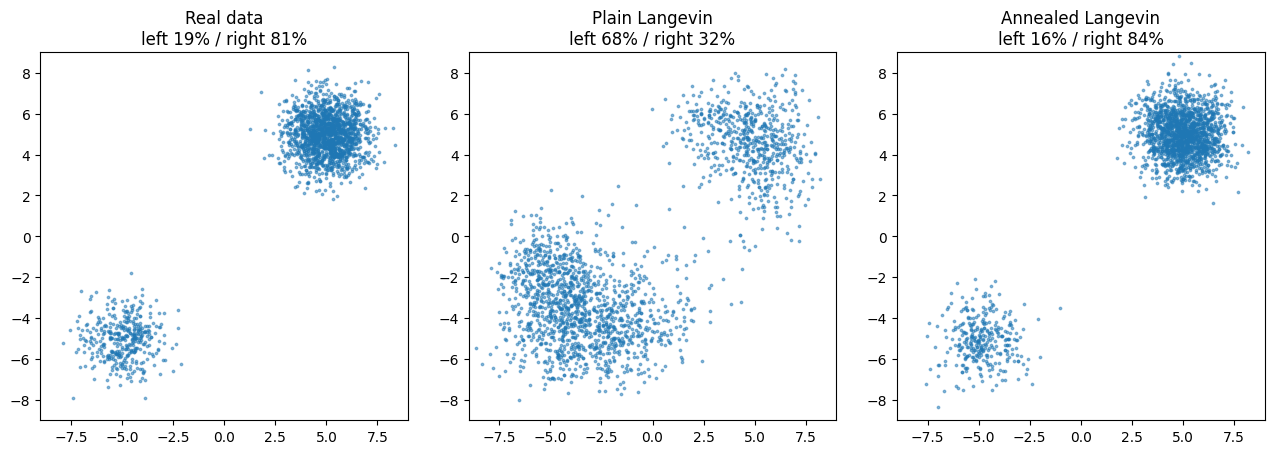

In [2]:
# Annealed Langevin sampling on 2D toy data (baseline)
# Based on: Song & Ermon 2019, "Generative Modeling by Estimating Gradients of the Data Distribution"
# Paste into one Kaggle notebook cell and run. No GPU needed.

import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------------
# 1. DATA: mixture of two Gaussians with UNEQUAL weights
#    20% of the data is around (-5,-5), 80% is around (5,5).
#    A good sampler must reproduce this 20/80 split.
# ---------------------------------------------------------------
WEIGHTS = torch.tensor([0.2, 0.8])
MEANS = torch.tensor([[-5.0, -5.0], [5.0, 5.0]])
DATA_STD = 1.0


def sample_data(n):
    k = torch.multinomial(WEIGHTS, n, replacement=True)   # which mode each point belongs to
    return MEANS[k] + DATA_STD * torch.randn(n, 2)


# ---------------------------------------------------------------
# 2. NOISE LEVELS: 10 levels, from large (20) to small (0.1)
# ---------------------------------------------------------------
L = 10
SIGMAS = torch.exp(torch.linspace(math.log(20.0), math.log(0.1), L)).to(device)
print("noise levels:", [round(s, 2) for s in SIGMAS.tolist()])


# ---------------------------------------------------------------
# 3. SCORE NETWORK: takes x and sigma, returns the score (2 numbers)
# ---------------------------------------------------------------
class ScoreNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, sigma):
        # sigma has shape (batch, 1)
        inp = torch.cat([x / 10.0, torch.log(sigma)], dim=1)   # simple input scaling
        return self.net(inp) / sigma                           # dividing by sigma makes training easier


# ---------------------------------------------------------------
# 4. TRAINING: denoising score matching
#    Take a data point x, add noise:  x_noisy = x + sigma * z
#    The network should predict the score of the noisy point, which is  -z / sigma
# ---------------------------------------------------------------
model = ScoreNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for it in range(1, 10001):
    x = sample_data(512).to(device)
    idx = torch.randint(0, L, (x.shape[0],), device=device)   # random noise level for each point
    sigma = SIGMAS[idx].unsqueeze(1)
    z = torch.randn_like(x)
    x_noisy = x + sigma * z

    score = model(x_noisy, sigma)
    loss = 0.5 * ((sigma * score + z) ** 2).sum(dim=1).mean()   # weighted by sigma^2, as in the paper

    opt.zero_grad()
    loss.backward()
    opt.step()
    if it % 2000 == 0:
        print(f"iter {it:5d}   loss {loss.item():.4f}")


# ---------------------------------------------------------------
# 5. SAMPLERS
# ---------------------------------------------------------------
@torch.no_grad()
def langevin_step(x, sigma, alpha):
    """One Langevin update of all particles at noise level sigma."""
    s = model(x, sigma.expand(x.shape[0], 1))
    return x + 0.5 * alpha * s + math.sqrt(alpha) * torch.randn_like(x)


@torch.no_grad()
def plain_langevin(n, n_steps, eps):
    """Plain Langevin: only the smallest noise level, same number of total steps."""
    x = (torch.rand(n, 2, device=device) - 0.5) * 16          # start uniform in [-8, 8]^2
    sigma = SIGMAS[-1]
    for _ in range(n_steps):
        x = langevin_step(x, sigma, eps)
    return x.cpu()


@torch.no_grad()
def annealed_langevin(n, steps_per_level, eps):
    """Annealed Langevin: go from the largest noise level to the smallest.
    steps_per_level can be one number (same T everywhere) or a list of L numbers."""
    if isinstance(steps_per_level, int):
        steps_per_level = [steps_per_level] * L
    x = (torch.rand(n, 2, device=device) - 0.5) * 16          # same starting points as plain Langevin
    for i in range(L):
        sigma = SIGMAS[i]
        alpha = eps * (sigma / SIGMAS[-1]) ** 2               # step size shrinks with the noise level
        for _ in range(steps_per_level[i]):
            x = langevin_step(x, sigma, alpha)
        # the particles at the end of this level are the start of the next level
    return x.cpu()


def mode_fractions(x):
    """Fraction of samples near (-5,-5) and near (5,5)."""
    left = (x.sum(dim=1) < 0).float().mean().item()
    return left, 1 - left


# ---------------------------------------------------------------
# 6. RUN AND COMPARE
# ---------------------------------------------------------------
N = 2000          # number of particles
T = 100           # Langevin steps per noise level
EPS = 0.002       # step size at the smallest noise level

real = sample_data(N)
plain = plain_langevin(N, n_steps=L * T, eps=EPS)             # 1000 steps in total
annealed = annealed_langevin(N, steps_per_level=T, eps=EPS)   # 10 levels x 100 steps = 1000 steps

print("\nfraction of samples in each mode (left, right):")
for name, s in [("real data", real), ("plain Langevin", plain), ("annealed Langevin", annealed)]:
    l, r = mode_fractions(s)
    print(f"  {name:18s} {l:.2f}  {r:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (name, s) in zip(axes, [("Real data", real), ("Plain Langevin", plain), ("Annealed Langevin", annealed)]):
    l, r = mode_fractions(s)
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.5)
    ax.set_title(f"{name}\nleft {l:.0%} / right {r:.0%}")
    ax.set_xlim(-9, 9)
    ax.set_ylim(-9, 9)
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("toy_result.png", dpi=120)
plt.show()


## 2. Step sweep: what goes wrong with fewer steps per level (T = 100, 50, 20, 10, 5)
Metrics: split error (share in the small mode vs 20%) and sliced Wasserstein distance.

In [3]:
import time

def sliced_wasserstein(a, b, n_proj=200):
    d = torch.randn(n_proj, 2)
    d = d / d.norm(dim=1, keepdim=True)
    pa = torch.sort(a @ d.T, dim=0).values
    pb = torch.sort(b @ d.T, dim=0).values
    return (pa - pb).abs().mean().item()


T_LIST = [100, 50, 20, 10, 5]
real = sample_data(N)
floor = sliced_wasserstein(real, sample_data(N))

results, samples = [], {}
for T in T_LIST:
    torch.manual_seed(1)
    t0 = time.time()
    x = annealed_langevin(N, steps_per_level=T, eps=EPS)
    elapsed = time.time() - t0
    left, _ = mode_fractions(x)
    results.append((T, L * T, left, abs(left - 0.2), sliced_wasserstein(x, real), elapsed))
    samples[T] = x

print(f"best possible SW distance (real vs real): {floor:.3f}\n")
for T, total, left, err, sw, t in results:
    print(f"{T:8d} {total:6d} {left:7.1%} {err:10.1%} {sw:8.3f} {t:9.3f}")


best possible SW distance (real vs real): 0.074

     100   1000   17.1%       2.9%    0.187     2.753
      50    500   19.1%       0.9%    0.136     1.372
      20    200   22.1%       2.1%    0.504     0.606
      10    100   28.5%       8.5%    1.134     0.285
       5     50   35.1%      15.1%    2.777     0.149


## 3. Birth-death with the exact potential V (oracle)
Lu, Lu & Nolen (2019) birth-death step after every noise level, using the true noisy density.

best possible SW distance: 0.074

                    left %         split err           SW dist          time (s)
 T/level     base       BD     base       BD     base       BD     base       BD
     100    17.1%    19.4%     2.9%     0.6%    0.187    0.090    2.753    3.241
      50    19.1%    20.0%     0.9%     0.0%    0.136    0.140    1.372    2.113
      20    22.1%    19.9%     2.1%     0.1%    0.504    0.164    0.606    1.181
      10    28.5%    19.6%     8.5%     0.4%    1.134    0.205    0.285    0.847
       5    35.1%    20.1%    15.1%     0.1%    2.777    0.374    0.149    0.725

unique samples out of 2000 (duplicates would mean lost diversity):
  T = 100   2000
  T =  50   2000
  T =  20   2000
  T =  10   2000
  T =   5   2000

birth/death events per particle at each noise level (T = 10):
  sigma =  20.00     0.97
  sigma =  11.10     0.98
  sigma =   6.16     0.95
  sigma =   3.42     0.79
  sigma =   1.90     0.47
  sigma =   1.05     0.25
  sigma =   0.58     0.11
 

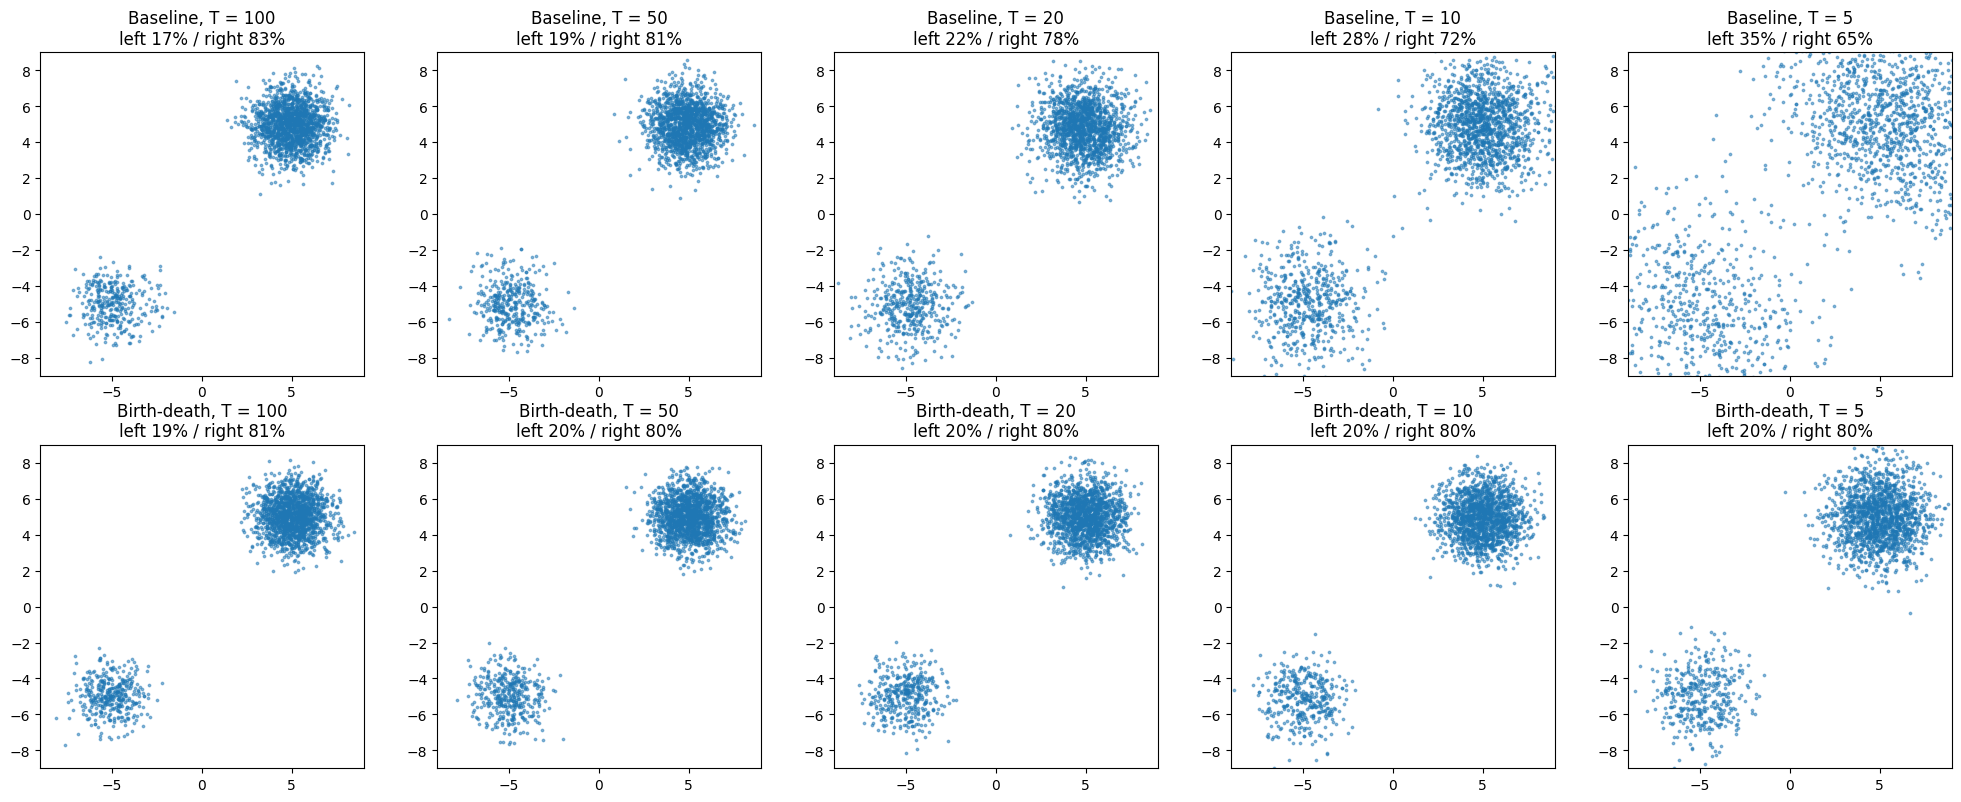

In [4]:
# ---------------------------------------------------------------
# BIRTH-DEATH + ANNEALED LANGEVIN
# Run after the T-sweep cell (uses results, T_LIST, real, sliced_wasserstein, ...)
# ---------------------------------------------------------------

def V_exact(x, sigma):
    """Option 1: exact V = -log p_sigma(x) for the toy data (constant dropped)."""
    var = DATA_STD ** 2 + sigma ** 2
    means, w = MEANS.to(x.device), WEIGHTS.to(x.device)
    d2 = ((x[:, None, :] - means[None, :, :]) ** 2).sum(-1)
    return -torch.logsumexp(torch.log(w)[None, :] - d2 / (2 * var), dim=1)


@torch.no_grad()
def birth_death_step(x, V, dt, k_nn=30):
    """One birth-death step for all particles at once
    (Algorithm 1 of Lu, Lu & Nolen 2019)."""
    n = x.shape[0]
    d2 = torch.cdist(x, x) ** 2                                   # squared distance between every pair

    # kernel width: median distance to the k-th nearest neighbour (adapts to each noise level).
    # Measured on 200 random particles only, because doing it for all of them is slow.
    sub = torch.randperm(n, device=x.device)[:200]
    h2 = torch.kthvalue(d2[sub], k_nn + 1, dim=1).values.median()
    log_rho = torch.logsumexp(-d2 / (2 * h2), dim=1)              # log of current particle density (up to a constant)

    beta = log_rho + V
    beta = beta - beta.mean()                                     # > 0: too crowded here, < 0: too few here

    p = 1 - torch.exp(-beta.abs() * dt)                           # chance of a birth/death event for each particle
    event = torch.rand(n, device=x.device) < p
    kill = event & (beta > 0)
    dup = event & (beta < 0)

    idx = torch.arange(n, device=x.device)
    # killed particle -> replaced by a copy of a random particle
    idx[kill] = torch.randint(0, n, (int(kill.sum()),), device=x.device)
    # duplicated particle -> its copy overwrites a random particle (keeps N fixed)
    dup_ids = dup.nonzero().squeeze(1)
    idx[torch.randint(0, n, (len(dup_ids),), device=x.device)] = dup_ids
    return x[idx], int(event.sum())


@torch.no_grad()
def annealed_langevin_bd(n, steps_per_level, eps, V_fn, bd_every=None, bd_rate=1.0, k_nn=30):
    """Annealed Langevin with a birth-death step after every `bd_every` Langevin steps.
    bd_every=None means once per noise level, at the END of the level."""
    if isinstance(steps_per_level, int):
        steps_per_level = [steps_per_level] * L
    x = (torch.rand(n, 2, device=device) - 0.5) * 16              # same start as the baseline
    events_per_level = []
    for i in range(L):
        sigma = SIGMAS[i]
        alpha = eps * (sigma / SIGMAS[-1]) ** 2
        T_i = steps_per_level[i]
        every = T_i if bd_every is None else bd_every
        n_events = 0
        for t in range(T_i):
            x = langevin_step(x, sigma, alpha)
            very_last_step = (i == L - 1 and t == T_i - 1)        # no BD here, or the output would contain exact copies
            if (t + 1) % every == 0 and not very_last_step:
                # our step x + (alpha/2)*score + sqrt(alpha)*z is the paper's step with dt = alpha/2;
                # one BD step stands in for `every` Langevin steps, so its time step is every * dt
                dt = bd_rate * every * alpha.item() / 2
                x, e = birth_death_step(x, V_fn(x, sigma.item()), dt, k_nn)
                n_events += e
        events_per_level.append(n_events / n)                     # births+deaths per particle at this level
    return x.cpu(), events_per_level


# ---------------- run and compare with the baseline ----------------
bd_results, bd_samples, bd_events = [], {}, {}
for T in T_LIST:
    torch.manual_seed(1)                                          # same starting points as the baseline
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    x, ev = annealed_langevin_bd(N, T, EPS, V_exact)
    if device == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - t0
    left, _ = mode_fractions(x)
    bd_results.append((T, left, abs(left - 0.2), sliced_wasserstein(x, real), elapsed))
    bd_samples[T], bd_events[T] = x, ev

print(f"best possible SW distance: {floor:.3f}\n")
print(f"{'':8s} {'left %':>17s} {'split err':>17s} {'SW dist':>17s} {'time (s)':>17s}")
print(f"{'T/level':>8s}" + "     base       BD" * 4)
for (T, _, l0, e0, s0, t0_), (_, l1, e1, s1, t1) in zip(results, bd_results):
    print(f"{T:8d} {l0:8.1%} {l1:8.1%} {e0:8.1%} {e1:8.1%} {s0:8.3f} {s1:8.3f} {t0_:8.3f} {t1:8.3f}")

print("\nunique samples out of", N, "(duplicates would mean lost diversity):")
for T in T_LIST:
    print(f"  T = {T:3d}   {torch.unique(bd_samples[T], dim=0).shape[0]}")

print("\nbirth/death events per particle at each noise level (T = 10):")
for s, e in zip(SIGMAS.tolist(), bd_events[10]):
    print(f"  sigma = {s:6.2f}   {e:6.2f}")

fig, axes = plt.subplots(2, len(T_LIST), figsize=(4 * len(T_LIST), 8))
for j, T in enumerate(T_LIST):
    for i, (name, x) in enumerate([("Baseline", samples[T]), ("Birth-death", bd_samples[T])]):
        ax = axes[i, j]
        left, _ = mode_fractions(x)
        ax.scatter(x[:, 0], x[:, 1], s=3, alpha=0.5)
        ax.set_title(f"{name}, T = {T}\nleft {left:.0%} / right {1-left:.0%}")
        ax.set_xlim(-9, 9)
        ax.set_ylim(-9, 9)
        ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## 4. Estimating V, option 2: energy network E(x, sigma)

iter  2000   loss 0.4538
iter  4000   loss 0.4174
iter  6000   loss 0.4895
iter  8000   loss 0.4807
iter 10000   loss 0.4794

V(left centre) - V(right centre):
   sigma     true  learned E
   20.00     0.15       0.11
   11.10     0.47       0.42
    6.16     1.14       1.05
    3.42     1.38       1.26
    1.90     1.39       1.05
    1.05     1.39       1.00
    0.58     1.39       1.56
    0.32     1.39       2.22
    0.18     1.39       2.83
    0.10     1.39       3.50

split error
                               T=100    T=50    T=20    T=10     T=5
ScoreNet, no BD                 2.9%    0.9%    2.1%    8.5%   15.1%
ScoreNet, BD, exact V           0.6%    0.0%    0.1%    0.4%    0.1%
EnergyNet, no BD                3.5%    6.0%    8.2%   13.3%   18.6%
EnergyNet, BD, V = E           11.7%    9.2%    2.9%    0.8%    2.9%
EnergyNet, BD, V = E, s>=2      0.6%    0.1%    2.6%    1.9%    4.4%

SW distance
                               T=100    T=50    T=20    T=10     T=5
ScoreNet, no

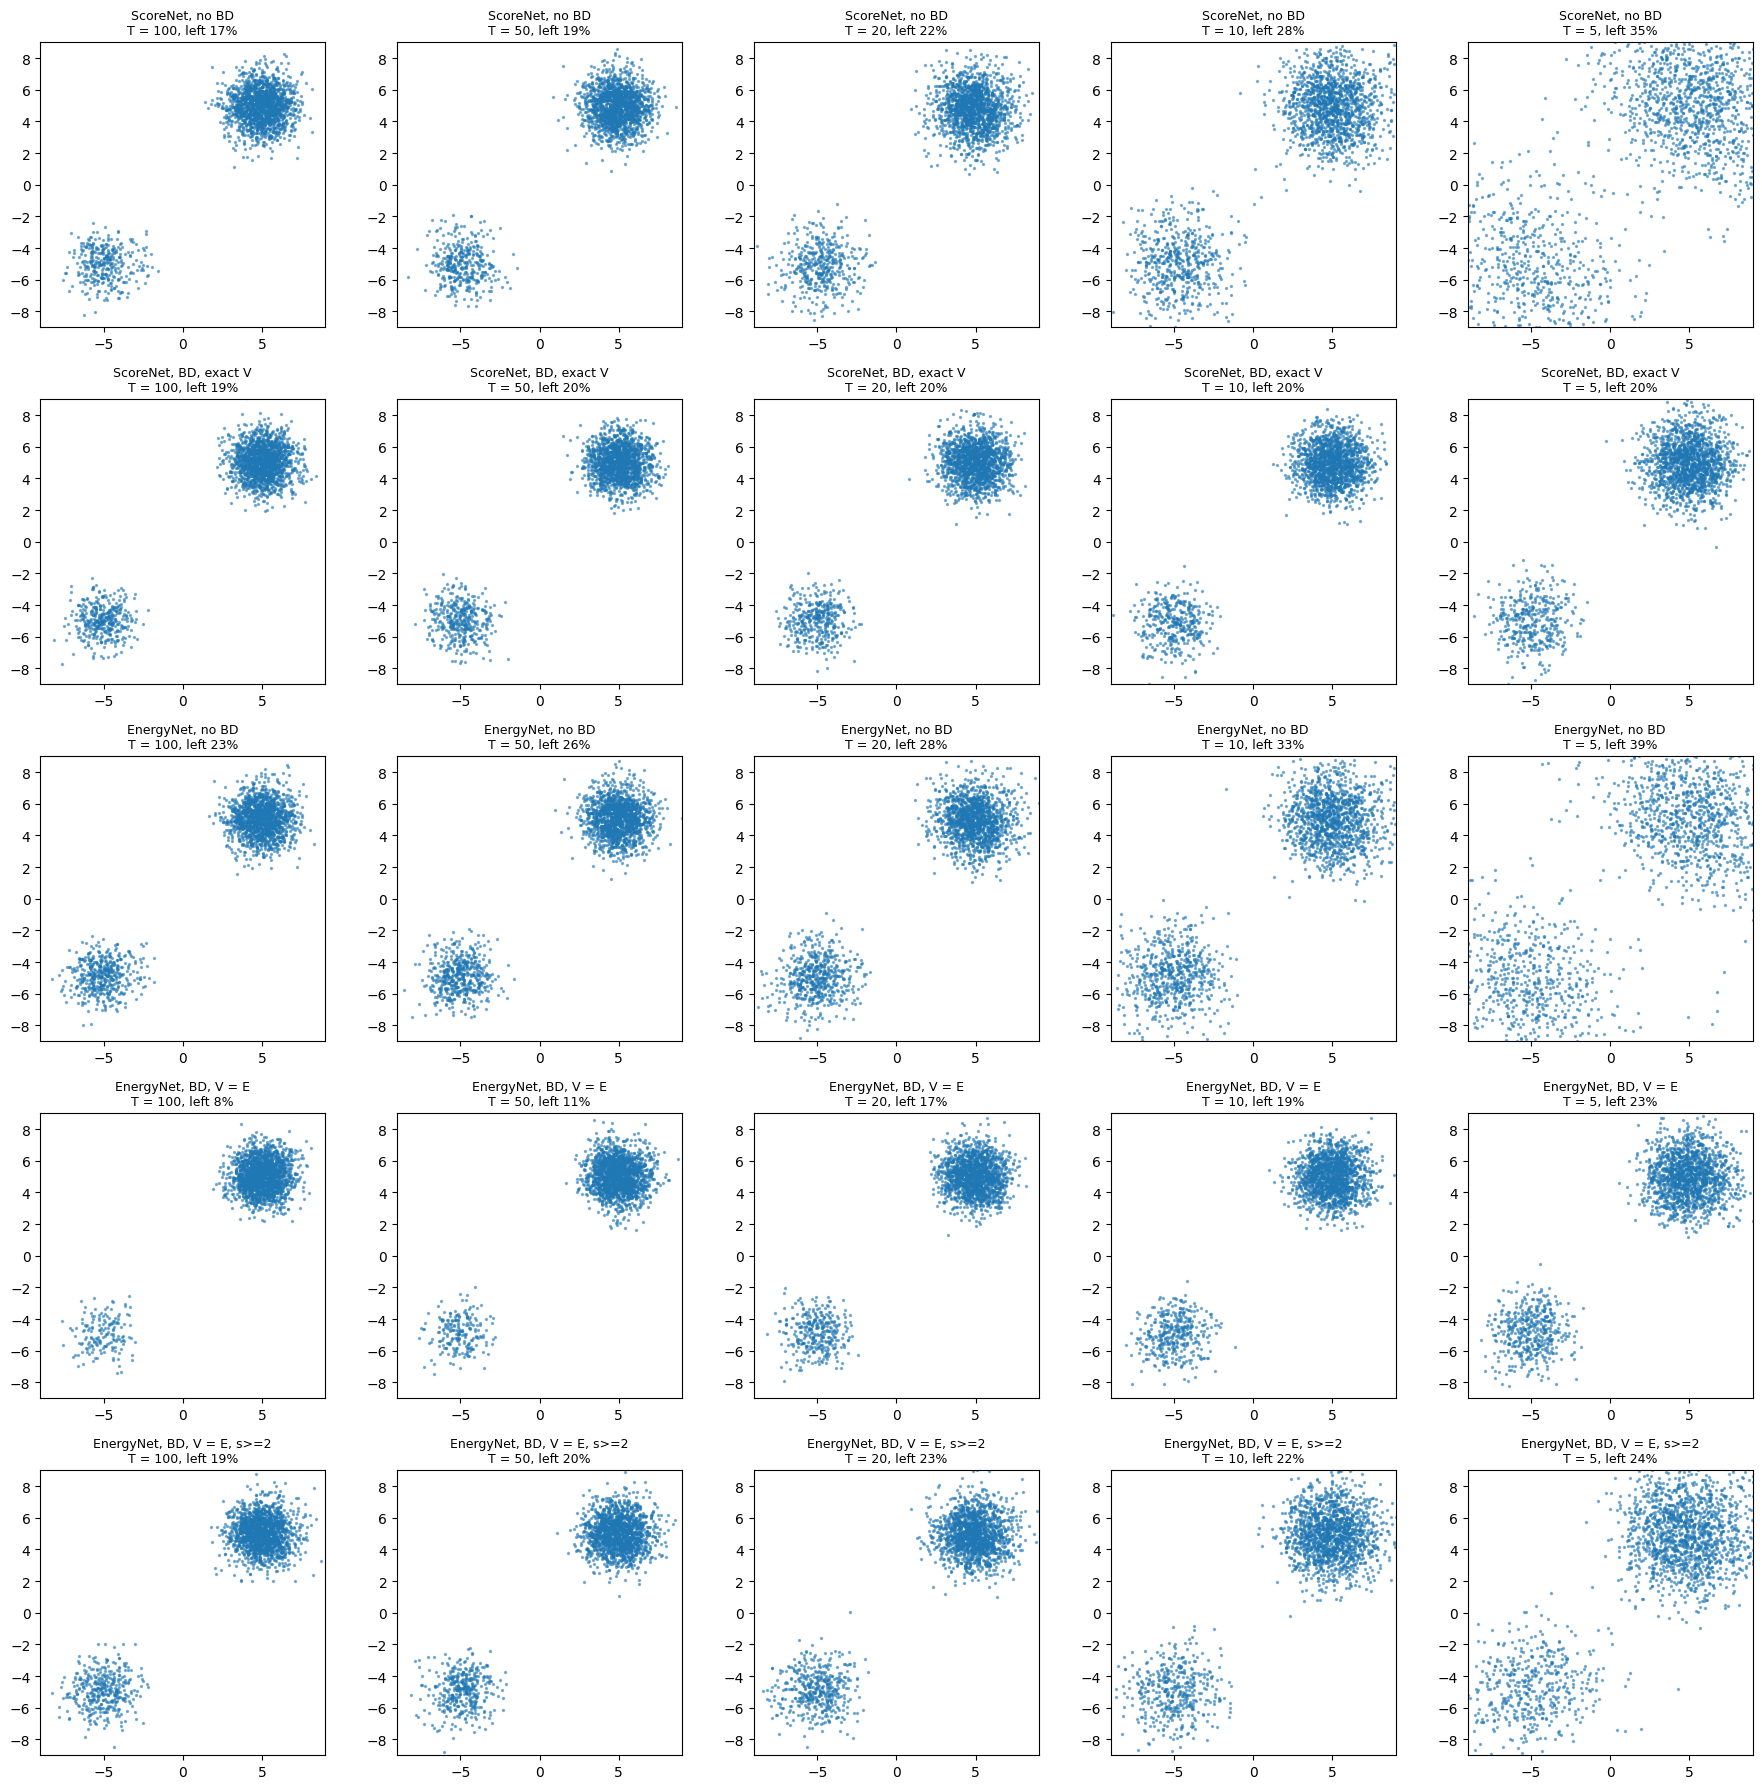

In [5]:
# ---------------------------------------------------------------
# OPTION 2: ENERGY NETWORK
# The network outputs ONE number E(x, sigma). Then:
#   score = -grad_x E   (used for the Langevin steps)
#   V     =  E          (used for birth-death)
# Run after the birth-death cell (uses birth_death_step, V_exact, results, bd_results, ...)
# ---------------------------------------------------------------

class EnergyNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1),                                  # one number, not two
        )

    def forward(self, x, sigma):
        # sigma has shape (batch, 1). Dividing x by sqrt(sigma^2 + 1) keeps the input
        # at a similar size for every noise level (same idea as x / 10 in ScoreNet).
        inp = torch.cat([x / torch.sqrt(sigma ** 2 + 1), torch.log(sigma)], dim=1)
        return self.net(inp).squeeze(1)


def energy_score(x, sigma):
    """score = -grad_x E, computed with autograd."""
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)
        E = enet(x, sigma)
        return -torch.autograd.grad(E.sum(), x)[0]


# ---------------- training: same denoising score matching loss as before ----------------
enet = EnergyNet().to(device)
opt_e = torch.optim.Adam(enet.parameters(), lr=1e-3)

for it in range(1, 10001):
    x = sample_data(512).to(device)
    idx = torch.randint(0, L, (x.shape[0],), device=device)
    sigma = SIGMAS[idx].unsqueeze(1)
    z = torch.randn_like(x)
    x_noisy = (x + sigma * z).requires_grad_(True)

    E = enet(x_noisy, sigma)
    score = -torch.autograd.grad(E.sum(), x_noisy, create_graph=True)[0]   # create_graph: so we can train through the gradient
    loss = 0.5 * ((sigma * score + z) ** 2).sum(dim=1).mean()

    opt_e.zero_grad()
    loss.backward()
    opt_e.step()
    if it % 2000 == 0:
        print(f"iter {it:5d}   loss {loss.item():.4f}")


@torch.no_grad()
def V_energy(x, sigma):
    """Option 2: V = E(x, sigma) from the energy network."""
    return enet(x, torch.full((x.shape[0], 1), sigma, device=x.device))


# ---------------- check 1: does the learned E get the gap between the modes right? ----------------
# V(left centre) - V(right centre). The true value is about log(0.8/0.2) = 1.39 at small sigma.
# This number is what tells birth-death that the left mode should have fewer particles.
centres = MEANS.to(device)
print("\nV(left centre) - V(right centre):")
print(f"{'sigma':>8} {'true':>8} {'learned E':>10}")
for s in SIGMAS.tolist():
    vt = V_exact(centres, s)
    ve = V_energy(centres, s)
    print(f"{s:8.2f} {(vt[0] - vt[1]).item():8.2f} {(ve[0] - ve[1]).item():10.2f}")


# ---------------- generic sampler: any score function, any V (or no birth-death) ----------------
@torch.no_grad()
def sample(n, T, eps, score_fn, V_fn=None, min_sigma=0.0):
    """min_sigma: only do birth-death at noise levels with sigma >= min_sigma."""
    x = (torch.rand(n, 2, device=device) - 0.5) * 16              # same start as before
    for i in range(L):
        sigma = SIGMAS[i]
        alpha = eps * (sigma / SIGMAS[-1]) ** 2
        for t in range(T):
            s = score_fn(x, sigma.expand(n, 1))
            x = x + 0.5 * alpha * s + torch.sqrt(alpha) * torch.randn_like(x)
        if V_fn is not None and i < L - 1 and sigma >= min_sigma:  # birth-death once per level, not after the last
            x, _ = birth_death_step(x, V_fn(x, sigma.item()), T * alpha.item() / 2)
    return x.cpu()


def score_net(x, sigma):
    return model(x, sigma)


configs = [   # (name, score function, V function, min_sigma)
    ("ScoreNet, no BD",           score_net,    None,     0.0),
    ("ScoreNet, BD, exact V",     score_net,    V_exact,  0.0),
    ("EnergyNet, no BD",          energy_score, None,     0.0),
    ("EnergyNet, BD, V = E",      energy_score, V_energy, 0.0),   # option 2: everything from one network
    ("EnergyNet, BD, V = E, s>=2", energy_score, V_energy, 2.0),  # option 2, BD only where E is reliable
]

table = {}
for name, score_fn, V_fn, min_sigma in configs:
    for T in T_LIST:
        torch.manual_seed(1)
        if device == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        x = sample(N, T, EPS, score_fn, V_fn, min_sigma)
        if device == "cuda":
            torch.cuda.synchronize()
        left, _ = mode_fractions(x)
        table[name, T] = (abs(left - 0.2), sliced_wasserstein(x, real), time.time() - t0, x)

for col, label, fmt in [(0, "split error", "{:8.1%}"), (1, "SW distance", "{:8.3f}"), (2, "time (s)", "{:8.2f}")]:
    print(f"\n{label}")
    print(f"{'':28s}" + "".join(f"{'T=' + str(T):>8s}" for T in T_LIST))
    for name, *_ in configs:
        print(f"{name:28s}" + "".join(fmt.format(table[name, T][col]) for T in T_LIST))

fig, axes = plt.subplots(len(configs), len(T_LIST), figsize=(3.6 * len(T_LIST), 3.6 * len(configs)))
for i, (name, *_) in enumerate(configs):
    for j, T in enumerate(T_LIST):
        x = table[name, T][3]
        left, _ = mode_fractions(x)
        ax = axes[i, j]
        ax.scatter(x[:, 0], x[:, 1], s=2, alpha=0.5)
        ax.set_title(f"{name}\nT = {T}, left {left:.0%}", fontsize=9)
        ax.set_xlim(-9, 9)
        ax.set_ylim(-9, 9)
        ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## 5. Estimating V, option 3: probability-flow ODE likelihood (score network only)

In [6]:
# ---------------------------------------------------------------
# OPTION 3: V FROM THE PROBABILITY-FLOW ODE (uses only the score network, no retraining)
# Idea: move the particle along  dx/dsigma = -sigma * score(x, sigma)  up to SIGMA_MAX,
# adding up the divergence of the score on the way. At SIGMA_MAX the density is almost a
# Gaussian, so log p is known there. Result: V(x) = -log p_sigma(x) at the original sigma.
# Run after the option 2 cell (uses sample, score_net, V_exact, T_LIST, real, ...)
# ---------------------------------------------------------------

SIGMA_MAX = SIGMAS[0].item()

# Gaussian at SIGMA_MAX: data mean and covariance, plus the noise
_data = sample_data(100000)
END_MEAN = _data.mean(0).to(device)
END_COV = (torch.cov(_data.T) + SIGMA_MAX ** 2 * torch.eye(2)).to(device)
end_dist = torch.distributions.MultivariateNormal(END_MEAN, END_COV)


def score_and_div(score_fn, x, sigma):
    """Score at x, and its divergence (d s1/d x1 + d s2/d x2), computed with autograd."""
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)
        s = score_fn(x, torch.full((x.shape[0], 1), sigma, device=x.device))
        div = sum(torch.autograd.grad(s[:, j].sum(), x, retain_graph=True)[0][:, j] for j in range(2))
    return s.detach(), div.detach()


def make_V_ode(score_fn, n_steps=10):
    """Returns a V function that birth-death can use, built from any score function.
    n_steps = ODE steps for the full range SIGMA_MIN -> SIGMA_MAX (fewer when starting higher)."""
    full_range = math.log(SIGMA_MAX / SIGMAS[-1].item())

    @torch.no_grad()
    def V_ode(x, sigma0):
        if sigma0 >= SIGMA_MAX:
            return -end_dist.log_prob(x)
        k = max(2, round(n_steps * math.log(SIGMA_MAX / sigma0) / full_range))
        grid = torch.exp(torch.linspace(math.log(sigma0), math.log(SIGMA_MAX), k + 1)).tolist()
        x = x.clone()
        int_div = torch.zeros(x.shape[0], device=x.device)
        for a, b in zip(grid[:-1], grid[1:]):              # Heun's method (2nd order) from sigma=a to sigma=b
            s_a, d_a = score_and_div(score_fn, x, a)
            x_pred = x - a * s_a * (b - a)
            s_b, d_b = score_and_div(score_fn, x_pred, b)
            x = x - 0.5 * (a * s_a + b * s_b) * (b - a)
            int_div += 0.5 * (a * d_a + b * d_b) * (b - a)
        return -(end_dist.log_prob(x) - int_div)            # V = -log p

    return V_ode


V_ode = make_V_ode(score_net)


# ---------------- check: the gap between the modes ----------------
centres = MEANS.to(device)
print("V(left centre) - V(right centre):")
print(f"{'sigma':>8} {'true':>8} {'ODE (ScoreNet)':>15}")
for s in SIGMAS.tolist():
    vt, vo = V_exact(centres, s), V_ode(centres, s)
    print(f"{s:8.2f} {(vt[0] - vt[1]).item():8.2f} {(vo[0] - vo[1]).item():15.2f}")


# ---------------- comparison table (reused by the next cell) ----------------
def run_table(configs, title=""):
    table = {}
    for name, score_fn, V_fn, min_sigma in configs:
        for T in T_LIST:
            torch.manual_seed(1)
            if device == "cuda":
                torch.cuda.synchronize()
            t0 = time.time()
            x = sample(N, T, EPS, score_fn, V_fn, min_sigma)
            if device == "cuda":
                torch.cuda.synchronize()
            left, _ = mode_fractions(x)
            table[name, T] = (abs(left - 0.2), sliced_wasserstein(x, real), time.time() - t0)
    print(f"\n===== {title} =====")
    for col, label, fmt in [(0, "split error", "{:8.1%}"), (1, "SW distance", "{:8.3f}"), (2, "time (s)", "{:8.2f}")]:
        print(f"\n{label}")
        print(f"{'':30s}" + "".join(f"{'T=' + str(T):>8s}" for T in T_LIST))
        for name, *_ in configs:
            print(f"{name:30s}" + "".join(fmt.format(table[name, T][col]) for T in T_LIST))
    return table


ode_table = run_table([
    ("ScoreNet, no BD",          score_net, None,    0.0),
    ("ScoreNet, BD, exact V",    score_net, V_exact, 0.0),
    ("ScoreNet, BD, V = ODE",    score_net, V_ode,   0.0),
], "Option 3: V from the ODE")


V(left centre) - V(right centre):
   sigma     true  ODE (ScoreNet)
   20.00     0.15            0.14
   11.10     0.47            0.49
    6.16     1.14            1.33
    3.42     1.38            1.61
    1.90     1.39            1.65
    1.05     1.39            1.71
    0.58     1.39            1.75
    0.32     1.39            1.76
    0.18     1.39            1.75
    0.10     1.39            1.76

===== Option 3: V from the ODE =====

split error
                                 T=100    T=50    T=20    T=10     T=5
ScoreNet, no BD                   2.9%    0.9%    2.1%    8.5%   15.1%
ScoreNet, BD, exact V             0.6%    0.0%    0.1%    0.4%    0.1%
ScoreNet, BD, V = ODE             3.8%    4.6%    3.5%    3.2%    3.1%

SW distance
                                 T=100    T=50    T=20    T=10     T=5
ScoreNet, no BD                  0.187   0.136   0.504   1.134   2.777
ScoreNet, BD, exact V            0.090   0.140   0.164   0.205   0.374
ScoreNet, BD, V = ODE          

## 6. Estimating V, option 2b: energy network + heat-equation loss

In [7]:
# ---------------------------------------------------------------
# OPTION 2b: ENERGY NETWORK + HEAT-EQUATION LOSS
# Noisy densities are not independent: p_sigma is p_0 blurred by noise of size sigma,
# so they must satisfy the heat equation  d p / d sigma = sigma * Laplacian(p).
# Written for E (where log p_sigma = -E + c(sigma), c unknown):
#     R(x, sigma) = dE/dlog(sigma) - sigma^2 * (Laplacian E - |grad E|^2)
# must be THE SAME NUMBER for every x (it equals sigma * c'(sigma)).
# Extra loss = variance of R over x, at points spread over the WHOLE plane,
# including between the modes where normal training has no data.
# This ties low-noise E to high-noise E, where the gap between modes is learned correctly.
# Run after the option 3 cell (uses EnergyNet, run_table, sample, make_V_ode, ...)
# ---------------------------------------------------------------

LAMBDA_HEAT = 1.0      # weight of the extra loss (try 0.1, 1, 10 in the ablation)
G, M = 8, 64           # extra loss uses G noise levels per batch, M points each


def heat_residual(net, x, log_sigma):
    """R(x, sigma) for every point. x: (n, 2), log_sigma: (n, 1)."""
    x = x.requires_grad_(True)
    log_sigma = log_sigma.requires_grad_(True)
    sigma = log_sigma.exp()
    E = net(x, sigma)
    gx, gls = torch.autograd.grad(E.sum(), (x, log_sigma), create_graph=True)
    lap = sum(torch.autograd.grad(gx[:, j].sum(), x, create_graph=True)[0][:, j] for j in range(2))
    return gls.squeeze(1) - sigma.squeeze(1) ** 2 * (lap - (gx ** 2).sum(1))


enet2 = EnergyNet().to(device)
opt_e2 = torch.optim.Adam(enet2.parameters(), lr=1e-3)
log_smin, log_smax = math.log(SIGMAS[-1].item()), math.log(SIGMAS[0].item())

for it in range(1, 10001):
    # (a) usual denoising score matching loss, same as option 2
    x = sample_data(512).to(device)
    idx = torch.randint(0, L, (x.shape[0],), device=device)
    sigma = SIGMAS[idx].unsqueeze(1)
    z = torch.randn_like(x)
    x_noisy = (x + sigma * z).requires_grad_(True)
    score = -torch.autograd.grad(enet2(x_noisy, sigma).sum(), x_noisy, create_graph=True)[0]
    loss_dsm = 0.5 * ((sigma * score + z) ** 2).sum(dim=1).mean()

    # (b) heat-equation loss: G random noise levels (any value, not just the 10), M points each,
    #     spread uniformly over the box [-10, 10]^2
    xr = (torch.rand(G * M, 2, device=device) - 0.5) * 20
    ls = log_smin + torch.rand(G, 1, device=device) * (log_smax - log_smin)
    ls = ls.repeat_interleave(M, dim=0)
    R = heat_residual(enet2, xr, ls).view(G, M)
    loss_heat = R.var(dim=1).mean()

    loss = loss_dsm + LAMBDA_HEAT * loss_heat
    opt_e2.zero_grad()
    loss.backward()
    opt_e2.step()
    if it % 2000 == 0:
        print(f"iter {it:5d}   DSM loss {loss_dsm.item():.4f}   heat loss {loss_heat.item():.4f}")


def energy_score2(x, sigma):
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)
        return -torch.autograd.grad(enet2(x, sigma).sum(), x)[0]


@torch.no_grad()
def V_energy2(x, sigma):
    return enet2(x, torch.full((x.shape[0], 1), sigma, device=x.device))


# ---------------- check: the gap between the modes ----------------
centres = MEANS.to(device)
print("\nV(left centre) - V(right centre):")
print(f"{'sigma':>8} {'true':>8} {'E (option 2)':>13} {'E + heat loss':>14}")
for s in SIGMAS.tolist():
    vt, v1, v2 = V_exact(centres, s), V_energy(centres, s), V_energy2(centres, s)
    print(f"{s:8.2f} {(vt[0] - vt[1]).item():8.2f} {(v1[0] - v1[1]).item():13.2f} {(v2[0] - v2[1]).item():14.2f}")

heat_table = run_table([
    ("EnergyNet, no BD",           energy_score,  None,      0.0),
    ("EnergyNet, BD, V = E",       energy_score,  V_energy,  0.0),
    ("EnergyNet+heat, no BD",      energy_score2, None,      0.0),
    ("EnergyNet+heat, BD, V = E",  energy_score2, V_energy2, 0.0),
], "Option 2b: energy network with heat-equation loss")


iter  2000   DSM loss 0.5391   heat loss 0.0061
iter  4000   DSM loss 0.4690   heat loss 0.0030
iter  6000   DSM loss 0.4571   heat loss 0.0018
iter  8000   DSM loss 0.5379   heat loss 0.0014
iter 10000   DSM loss 0.5348   heat loss 0.0007

V(left centre) - V(right centre):
   sigma     true  E (option 2)  E + heat loss
   20.00     0.15          0.11           0.16
   11.10     0.47          0.42           0.50
    6.16     1.14          1.05           1.21
    3.42     1.38          1.26           1.52
    1.90     1.39          1.05           1.58
    1.05     1.39          1.00           1.63
    0.58     1.39          1.56           1.64
    0.32     1.39          2.22           1.62
    0.18     1.39          2.83           1.59
    0.10     1.39          3.50           1.54

===== Option 2b: energy network with heat-equation loss =====

split error
                                 T=100    T=50    T=20    T=10     T=5
EnergyNet, no BD                  3.5%    6.0%    8.2%   13.3

## 7. Timing benchmark (warm-up + median of repeats)

In [8]:
# ---------------------------------------------------------------
# TIMING BENCHMARK
# Clean timing of every sampler setup: warm-up run first, then the median of REPEATS runs.
# Splits the time into: Langevin steps / computing V / the birth-death step itself.
# Run in a FRESH session after the training cells (nothing else running),
# with the GPU switched on (Kaggle: Settings -> Accelerator).
# ---------------------------------------------------------------
import statistics

REPEATS = 5
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU only")


def sync():
    if device == "cuda":
        torch.cuda.synchronize()


class Counted:
    """Wraps a score function and counts how often it is called (= network evaluations)."""
    def __init__(self, fn):
        self.fn, self.calls = fn, 0

    def __call__(self, x, sigma):
        self.calls += 1
        return self.fn(x, sigma)


@torch.no_grad()
def sample_timed(n, T, eps, score_fn, V_fn=None, min_sigma=0.0):
    """Same sampler as sample(), but measures where the time goes."""
    t_lang = t_V = t_bd = 0.0
    x = (torch.rand(n, 2, device=device) - 0.5) * 16
    for i in range(L):
        sigma = SIGMAS[i]
        alpha = eps * (sigma / SIGMAS[-1]) ** 2
        sync(); t0 = time.perf_counter()
        for t in range(T):
            s = score_fn(x, sigma.expand(n, 1))
            x = x + 0.5 * alpha * s + torch.sqrt(alpha) * torch.randn_like(x)
        sync(); t1 = time.perf_counter()
        t_lang += t1 - t0
        if V_fn is not None and i < L - 1 and sigma >= min_sigma:
            V = V_fn(x, sigma.item())
            sync(); t2 = time.perf_counter()
            x, _ = birth_death_step(x, V, T * alpha.item() / 2)
            sync(); t3 = time.perf_counter()
            t_V += t2 - t1
            t_bd += t3 - t2
    return x.cpu(), t_lang, t_V, t_bd


def benchmark(name, make, T):
    """make() returns (score_fn, V_fn); a fresh counter each time."""
    sample_timed(N, T, EPS, *make())                       # warm-up, not timed
    runs = []
    for r in range(REPEATS):
        torch.manual_seed(r)
        score_fn, V_fn = make()
        x, tl, tv, tb = sample_timed(N, T, EPS, score_fn, V_fn)
        left, _ = mode_fractions(x)
        runs.append((tl + tv + tb, tl, tv, tb, score_fn.calls, abs(left - 0.2), sliced_wasserstein(x, real)))
    med = lambda k: statistics.median(r[k] for r in runs)
    return dict(total=med(0), lang=med(1), V=med(2), bd=med(3), calls=runs[0][4], err=med(5), sw=med(6))


# Each setup: name -> function returning (counted score function, V function or None)
def setup_plain():
    return Counted(score_net), None

def setup_exact():
    return Counted(score_net), V_exact

def setup_ode():
    f = Counted(score_net)
    return f, make_V_ode(f)                                # ODE calls are counted too

setups = [("ScoreNet, no BD", setup_plain),
          ("ScoreNet, BD, exact V", setup_exact),
          ("ScoreNet, BD, V = ODE", setup_ode)]
if "enet2" in globals():                                   # only if the heat-loss cell was run
    setups.append(("EnergyNet+heat, BD, V = E", lambda: (Counted(energy_score2), V_energy2)))

bench = {}
for name, make in setups:
    for T in T_LIST:
        bench[name, T] = benchmark(name, make, T)

base = bench["ScoreNet, no BD", 100]["total"]
print(f"\nmedian of {REPEATS} runs, N = {N} particles. 'speed-up' is against ScoreNet, no BD, T = 100.\n")
print(f"{'setup':28s} {'T':>4s} {'net calls':>9s} {'total s':>8s} {'Langevin':>9s} {'V':>7s} {'BD step':>8s}"
      f" {'speed-up':>9s} {'split err':>10s} {'SW':>6s}")
for name, _ in setups:
    for T in T_LIST:
        b = bench[name, T]
        print(f"{name:28s} {T:4d} {b['calls']:9d} {b['total']:8.3f} {b['lang']:9.3f} {b['V']:7.3f} {b['bd']:8.3f}"
              f" {base / b['total']:8.1f}x {b['err']:10.1%} {b['sw']:6.3f}")
    print()


device: cpu | CPU only

median of 5 runs, N = 2000 particles. 'speed-up' is against ScoreNet, no BD, T = 100.

setup                           T net calls  total s  Langevin       V  BD step  speed-up  split err     SW
ScoreNet, no BD               100      1000    2.557     2.557   0.000    0.000      1.0x       3.2%  0.190
ScoreNet, no BD                50       500    1.286     1.286   0.000    0.000      2.0x       0.9%  0.158
ScoreNet, no BD                20       200    0.518     0.518   0.000    0.000      4.9x       3.1%  0.515
ScoreNet, no BD                10       100    0.255     0.255   0.000    0.000     10.0x       8.7%  1.198
ScoreNet, no BD                 5        50    0.125     0.125   0.000    0.000     20.5x      15.1%  2.773

ScoreNet, BD, exact V         100      1000    3.154     2.587   0.004    0.563      0.8x       0.7%  0.090
ScoreNet, BD, exact V          50       500    1.828     1.257   0.004    0.557      1.4x       0.9%  0.072
ScoreNet, BD, exact V   

## 8. Birth-death with a noise-aware classifier (density ratio of the two modes, label-shift EM)

In [9]:
# TOY CELL 08: birth-death with the density ratio from a noise-aware classifier (+ label-shift EM).
# Run after cells 01-03 (uses model, langevin_step, sample_data, SIGMAS, L, EPS, N, real, mode_fractions,
# sliced_wasserstein, birth_death_step, V_exact).
import time
import torch.nn.functional as F
torch.manual_seed(0)
# noisy classifier p(mode | x, sigma)
def sample_data_lab(n):
    k = torch.multinomial(WEIGHTS, n, replacement=True)
    return MEANS[k] + DATA_STD * torch.randn(n, 2), k
clf = nn.Sequential(nn.Linear(3, 64), nn.SiLU(), nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 2))
def clf_logits(x, s):
    return clf(torch.cat([x / torch.sqrt(s**2 + 1), torch.log(s)], 1))
opt = torch.optim.Adam(clf.parameters(), 1e-3)
lo, hi = math.log(0.1), math.log(20)
for it in range(3000):
    x, k = sample_data_lab(512)
    s = torch.exp(lo + (hi - lo) * torch.rand(512, 1))
    loss = F.cross_entropy(clf_logits(x + s * torch.randn_like(x), s), k)
    opt.zero_grad(); loss.backward(); opt.step()
pi = WEIGHTS.clone()
@torch.no_grad()
def bd_clf(x, sigma, dt):
    P = torch.softmax(clf_logits(x, torch.full((x.shape[0], 1), sigma)), 1)
    A = P / pi; m = P.mean(0)
    for _ in range(30):
        R = A * m; R = R / R.sum(1, keepdim=True); m = R.mean(0)
    lr = torch.log((A * m).sum(1)) - torch.log((A * pi).sum(1))
    beta = lr - lr.mean(); n = x.shape[0]
    p = 1 - torch.exp(-beta.abs() * dt); event = torch.rand(n) < p
    kill = event & (beta > 0); dup = event & (beta < 0)
    idx = torch.arange(n); idx[kill] = torch.randint(0, n, (int(kill.sum()),))
    d = dup.nonzero().squeeze(1); idx[torch.randint(0, n, (len(d),))] = d
    return x[idx]
@torch.no_grad()
def run(T, mode, seed):
    torch.manual_seed(seed)
    x = (torch.rand(N, 2) - 0.5) * 16
    for i in range(L):
        sigma = SIGMAS[i]; alpha = EPS * (sigma / SIGMAS[-1]) ** 2
        for t in range(T):
            x = langevin_step(x, sigma, alpha)
        if i < L - 1 and mode != "base":
            dt = T * alpha.item() / 2
            if mode == "exact": x, _ = birth_death_step(x, V_exact(x, sigma.item()), dt)
            else: x = bd_clf(x, sigma.item(), dt)
    return x
print(f"{'T':>4} {'baseline':>10} {'BD exact V':>11} {'BD classifier':>14}   (split error, mean of 3 seeds; SW in brackets)")
for T in [100, 50, 20, 10, 5]:
    out = []
    for mode in ["base", "exact", "clf"]:
        e = []; w = []
        for seed in [1, 2, 3]:
            x = run(T, mode, seed); l, _ = mode_fractions(x); e.append(abs(l - 0.2)); w.append(sliced_wasserstein(x, real))
        out.append(f"{sum(e)/3:6.1%} ({sum(w)/3:.2f})")
    print(f"{T:4d} " + "  ".join(out))


   T   baseline  BD exact V  BD classifier   (split error, mean of 3 seeds; SW in brackets)
 100   3.2% (0.21)    0.6% (0.12)    2.5% (0.17)
  50   1.1% (0.18)    0.8% (0.09)    1.1% (0.18)
  20   2.9% (0.53)    0.9% (0.12)    0.6% (0.33)
  10   8.3% (1.14)    0.7% (0.18)    0.2% (0.57)
   5  15.2% (2.78)    0.7% (0.40)    0.5% (1.57)


## 9. Birth-death with kNN in denoised space (label-free density ratio)

In [10]:
# TOY CELL 09: birth-death with the density ratio from k nearest neighbours between denoised particles and
# denoised noisy real data. Run after cell 08 (uses bd_clf for the comparison).
REF = sample_data(5000)                      # training data (fixed), reused at every level
@torch.no_grad()
def bd_knn(x, sigma, dt, k=20):
    """Ratio rho/p_sigma by k-NN between particles and noisy reference data, both mapped through
    the score model's denoiser phi(x) = x + sigma^2 s(x, sigma) (same map -> density ratio preserved)."""
    n = x.shape[0]
    sig = torch.full((n, 1), sigma)
    ref = REF + sigma * torch.randn_like(REF)
    phi_p = x + sigma**2 * model(x, sig)
    phi_r = ref + sigma**2 * model(ref, torch.full((len(ref), 1), sigma))
    d = torch.cdist(phi_p, torch.cat([phi_p, phi_r]))
    d[torch.arange(n), torch.arange(n)] = float("inf")
    nn_idx = d.topk(k, largest=False).indices
    a = (nn_idx < n).sum(1).float(); b = k - a
    lr = torch.log((a + 0.5) / n) - torch.log((b + 0.5) / len(ref))
    beta = lr - lr.mean()
    p = 1 - torch.exp(-beta.abs() * dt); event = torch.rand(n) < p
    kill = event & (beta > 0); dup = event & (beta < 0)
    idx = torch.arange(n); idx[kill] = torch.randint(0, n, (int(kill.sum()),))
    dd = dup.nonzero().squeeze(1); idx[torch.randint(0, n, (len(dd),))] = dd
    return x[idx]
@torch.no_grad()
def run2(T, mode, seed):
    torch.manual_seed(seed)
    x = (torch.rand(N, 2) - 0.5) * 16
    for i in range(L):
        sigma = SIGMAS[i]; alpha = EPS * (sigma / SIGMAS[-1]) ** 2
        for t in range(T):
            x = langevin_step(x, sigma, alpha)
        if i < L - 1 and mode != "base":
            dt = T * alpha.item() / 2
            if mode == "exact": x, _ = birth_death_step(x, V_exact(x, sigma.item()), dt)
            elif mode == "clf": x = bd_clf(x, sigma.item(), dt)
            else: x = bd_knn(x, sigma.item(), dt)
    return x
print(f"{'T':>4} {'baseline':>13} {'BD exact V':>13} {'BD classifier':>13} {'BD kNN-denoised':>15}  split err (SW)")
for T in [100, 20, 10, 5]:
    out = []
    for mode in ["base", "exact", "clf", "knn"]:
        e = []; w = []
        for seed in [1, 2, 3]:
            x = run2(T, mode, seed); l, _ = mode_fractions(x); e.append(abs(l - 0.2)); w.append(sliced_wasserstein(x, real))
        out.append(f"{sum(e)/3:5.1%} ({sum(w)/3:.2f})")
    print(f"{T:4d}  " + "  ".join(f"{o:>13s}" for o in out))


   T      baseline    BD exact V BD classifier BD kNN-denoised  split err (SW)
 100    3.2% (0.21)    0.6% (0.12)    2.5% (0.17)    0.4% (0.18)
  20    2.9% (0.53)    0.9% (0.12)    0.6% (0.33)    0.6% (0.24)
  10    8.3% (1.14)    0.7% (0.18)    0.2% (0.57)    0.4% (0.31)
   5   15.2% (2.78)    0.7% (0.40)    0.5% (1.57)    1.1% (0.51)


In [12]:
e, w = [], []
for seed in [1, 2, 3]:
    x = run2(50, "knn", seed); l, _ = mode_fractions(x)
    e.append(abs(l - 0.2)); w.append(sliced_wasserstein(x, real))
print(f"T=50 BD kNN: split err {sum(e)/3:.1%}  SW {sum(w)/3:.2f}")

T=50 BD kNN: split err 0.6%  SW 0.18


## Save outputs

In [11]:
import shutil
shutil.make_archive('toy_outputs', 'zip', 'figs_toy')
print('saved toy_outputs.zip with', len(os.listdir('figs_toy')), 'figures')

saved toy_outputs.zip with 3 figures
